# 03 · Baselines: does "who will buy" pick the right clients?

Four strategies, all with the **same features** (client attributes + basic pre-campaign activity from step 2) and the
**same base learner** (a scikit-learn `Pipeline`: imputation → log/scaling → one-hot → logistic regression):

| Strategy | Score used to rank clients |
|---|---|
| random | nothing (the "send to a random 10%" benchmark) |
| response model | P(buy \| contacted), trained on last campaign's contacted clients. **What most teams do.** |
| S-learner | one model with treatment as a feature, uplift = P(buy\|x, SMS) − P(buy\|x, no SMS) |
| T-learner | two models (SMS / no SMS), uplift = difference |
| class transformation | one model on z = 1 for (SMS, bought) and (no SMS, not bought); uplift = 2·P(z) − 1 |

Evaluated on the **validation split** (40,008 clients). The test split stays untouched until step 6.
Intervals: 95% paired bootstrap (300 resamples).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from uplift.dataset import assign_splits, build_base_table
from uplift.metrics import evaluate, qini_curve, uplift_at_k
from uplift.models import fit_score_all

FIG = ROOT / "reports" / "figures"
customers = pd.read_parquet(ROOT / "data" / "processed" / "customers.parquet")
train, valid = customers[customers.split == "train"], customers[customers.split == "valid"]
t_va, y_va = valid.treatment_flg.to_numpy(), valid.target.to_numpy()
ate = y_va[t_va == 1].mean() - y_va[t_va == 0].mean()
print(f"train {len(train):,}  valid {len(valid):,}  validation ATE = {ate*100:+.2f} pp")

train 120,023  valid 40,008  validation ATE = +3.32 pp


## 1. Results

In [2]:
scores = fit_score_all(train, valid)
rep = evaluate(scores, t_va, y_va, ks=(0.1, 0.3), n_boot=300, reference="response model")

def fmt(m, lo, hi, scale, dec):
    return f"{m*scale:.{dec}f} [{lo*scale:.{dec}f}, {hi*scale:.{dec}f}]"

table = pd.DataFrame({
    col: [fmt(rep.metrics.loc[m, col], rep.ci_low.loc[m, col], rep.ci_high.loc[m, col],
              1000 if col == "qini" else 100, 2) for m in rep.metrics.index]
    for col in rep.metrics.columns}, index=rep.metrics.index)
table.columns = ["uplift in top 10% (pp)", "uplift in top 30% (pp)", "Qini ×1000"]
table

,uplift in top 10% (pp),uplift in top 30% (pp),Qini ×1000
random,"0.72 [-2.03, 3.53]","3.26 [1.44, 4.99]","-0.49 [-1.74, 0.76]"
response model,"0.39 [-1.10, 1.55]","1.42 [0.24, 2.56]","-2.18 [-3.41, -0.97]"
S-learner,"6.28 [3.23, 9.43]","5.28 [3.37, 7.12]","2.39 [1.17, 3.85]"
T-learner,"10.23 [7.15, 13.22]","6.46 [4.65, 8.38]","3.03 [1.66, 4.48]"
class transformation,"9.36 [6.29, 12.38]","6.64 [4.60, 8.35]","3.01 [1.62, 4.38]"


Paired difference to the response model (same bootstrap resamples; an interval that excludes 0 means the
difference is real, not noise):

In [3]:
rep.vs_reference.drop(index="response model")

,uplift@10%,uplift@30%,qini
random,"+0.0033 [-0.0285, +0.0333]","+0.0184 [-0.0003, +0.0380]","+0.0017 [-0.0001, +0.0035]"
S-learner,"+0.0588 [+0.0246, +0.0956]","+0.0387 [+0.0173, +0.0624]","+0.0046 [+0.0025, +0.0068]"
T-learner,"+0.0984 [+0.0632, +0.1339]","+0.0505 [+0.0320, +0.0724]","+0.0052 [+0.0032, +0.0072]"
class transformation,"+0.0897 [+0.0577, +0.1252]","+0.0522 [+0.0313, +0.0729]","+0.0052 [+0.0032, +0.0072]"


## 2. Qini curves

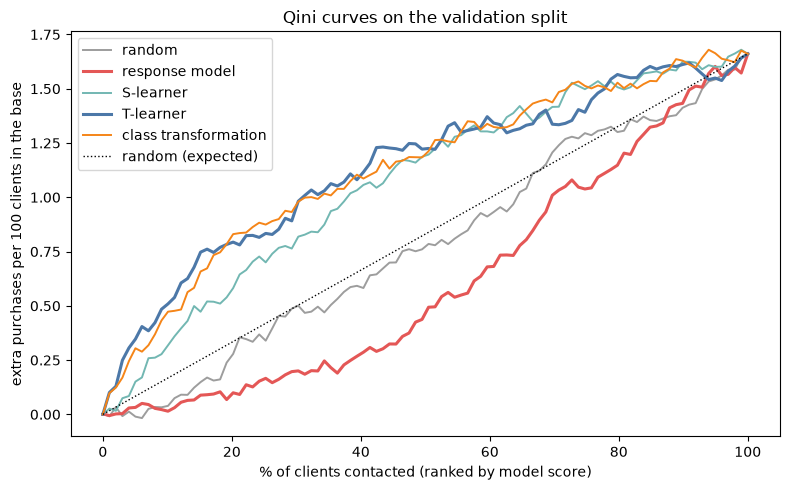

In [4]:
colors = {"random": "#9D9D9D", "response model": "#E45756", "S-learner": "#72B7B2",
          "T-learner": "#4C78A8", "class transformation": "#F58518"}
fig, ax = plt.subplots(figsize=(8, 5))
for name, s in scores.items():
    x, q = qini_curve(s, t_va, y_va)
    ax.plot(x * 100, q * 100, label=name, color=colors[name], lw=2.2 if name in ("T-learner", "response model") else 1.4)
ax.plot([0, 100], [0, q[-1] * 100], color="black", ls=":", lw=1, label="random (expected)")
ax.set_xlabel("% of clients contacted (ranked by model score)")
ax.set_ylabel("extra purchases per 100 clients in the base")
ax.set_title("Qini curves on the validation split")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "03_qini_baselines.png", dpi=150); plt.show()

## 3. Why the response model fails

It ranks clients by *how likely they are to buy*. The clients it puts on top buy almost always, **with or without the SMS**,
so the message changes nothing for them. Effect and purchase rates by score decile:

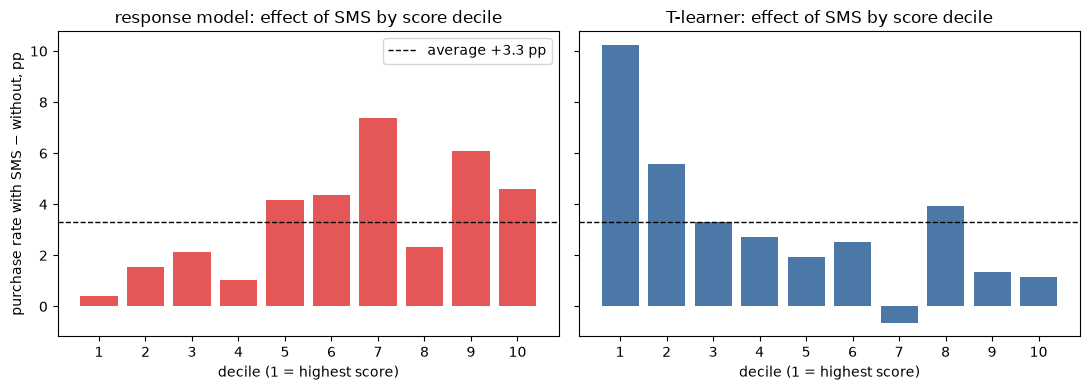

response model                             T-learner                \
       rate_without_sms rate_with_sms effect rate_without_sms rate_with_sms   
decile                                                                        
1                 0.948         0.952  0.004            0.421         0.524   
2                 0.866         0.881  0.015            0.482         0.538   
9                 0.322         0.383  0.061            0.732         0.746   
10                0.233         0.279  0.046            0.623         0.635   

               
       effect  
decile         
1       0.102  
2       0.056  
9       0.013  
10      0.012

In [5]:
def by_decile(score):
    d = pd.DataFrame({"s": score, "t": t_va, "y": y_va})
    d["decile"] = pd.qcut(-pd.Series(score).rank(method="first"), 10, labels=range(1, 11)).to_numpy()
    g = d.groupby("decile", observed=True)
    return pd.DataFrame({
        "rate_without_sms": g.apply(lambda x: x.y[x.t == 0].mean(), include_groups=False),
        "rate_with_sms": g.apply(lambda x: x.y[x.t == 1].mean(), include_groups=False),
    }).assign(effect=lambda x: x.rate_with_sms - x.rate_without_sms)

dec_resp, dec_t = by_decile(scores["response model"]), by_decile(scores["T-learner"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, dd) in zip(axes, [("response model", dec_resp), ("T-learner", dec_t)]):
    ax.bar(dd.index.astype(int), dd.effect * 100, color=colors[name])
    ax.axhline(ate * 100, color="black", ls="--", lw=1, label=f"average {ate*100:+.1f} pp")
    ax.set_title(f"{name}: effect of SMS by score decile")
    ax.set_xlabel("decile (1 = highest score)"); ax.set_xticks(range(1, 11))
axes[0].set_ylabel("purchase rate with SMS − without, pp"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "03_effect_by_decile.png", dpi=150); plt.show()

pd.concat({"response model": dec_resp, "T-learner": dec_t}, axis=1).loc[[1, 2, 9, 10]].round(3)

The response model's top decile is full of **sure things**: they buy anyway, and the SMS adds almost nothing.
The T-learner's top decile has a lower base rate but a much larger effect: these are the **persuadables**.

## 4. How much would the leaky column have inflated the result?

Same pipeline, but built with the raw `first_redeem_date`, which reaches 8 months past the campaign (see notebook 01).

In [6]:
from uplift.models import ClassTransformation, TLearner

leaky = assign_splits(build_base_table(censor_redeem=False))
assert (leaky.client_id.to_numpy() == customers.client_id.to_numpy()).all()
l_train, l_valid = leaky[leaky.split == "train"], leaky[leaky.split == "valid"]

rows = []
for learner, kind in [("logistic regression", "logistic"), ("gradient boosting", "boosting")]:
    for version, (tr, va) in [("clean", (train, valid)), ("leaky", (l_train, l_valid))]:
        s = fit_score_all(tr, va, models=[TLearner, ClassTransformation], learner=kind)
        m = evaluate(s, va.treatment_flg, va.target, n_boot=0).metrics
        for model in m.index:
            rows.append((learner, model, version, m.loc[model, "qini"] * 1000, m.loc[model, "uplift@10%"] * 100))
leak = (pd.DataFrame(rows, columns=["learner", "model", "version", "Qini ×1000", "uplift@10% pp"])
        .pivot_table(index=["learner", "model"], columns="version", values=["Qini ×1000", "uplift@10% pp"]))
leak[("Qini ×1000", "inflation ×")] = leak[("Qini ×1000", "leaky")] / leak[("Qini ×1000", "clean")]
leak.round(2)

Qini ×1000       uplift@10% pp  \
version                                       clean leaky         clean   
learner             model                                                 
gradient boosting   T-learner                  2.33  4.48         11.72   
                    class transformation       1.90  5.46          9.16   
logistic regression T-learner                  3.03  3.36         10.23   
                    class transformation       3.01  3.23          9.36   

                                                 Qini ×1000  
version                                   leaky inflation ×  
learner             model                                    
gradient boosting   T-learner             14.86        1.92  
                    class transformation  17.61        2.87  
logistic regression T-learner             10.06        1.11  
                    class transformation   9.51        1.07

With a linear learner the leak inflates Qini only slightly. **A flexible learner finds it and the offline
Qini more than doubles**, which looks like a large modelling win but is an artefact: at scoring time a future redemption
date does not exist, so the model would underperform in production. All further steps use the censored table.

## Conclusions

* **The response model is no better than random targeting** for this campaign: it spends the SMS budget on clients
  who buy anyway (95% of its top decile buy without the SMS).
* **Uplift models with the same features and the same simple learner roughly triple the effect** in the top 10%
  compared with the average (see the table). The paired intervals against the response model exclude zero.
* T-learner and class transformation are statistically indistinguishable here; the S-learner is weaker because a linear
  model with treatment as one extra feature can barely express *who* reacts.
* Business translation: contacting the top 10% by T-learner yields roughly 3× the extra purchases per SMS compared with
  sending to a random 10%.
* On the clean data gradient boosting is *not* better than logistic regression with these few features; non-linear
  learners only pay off with richer inputs.
* Next: step 4 adds behavioural features from the 45.8M-row purchase log; step 5 tunes non-linear learners.